# Grokking on MNIST: first look

This notebook plots the basic picture of grokking on MNIST for the bias-free three layer network. It reads the runs saved by the exploration in `exploration/results/`, so it trains nothing and runs in under a minute. The full grid sweep, `mnist_sweep.py`, will write its tables to `sweep/`, and later notebooks can read those instead.

**Events.** These follow `mnist_sweep.py`. Memorisation is the first checkpoint with training accuracy at least 0.99 (golden report section 3.5). MNIST does not reach the report's test levels of 0.90 and 0.95 reliably, so the grokking event for MNIST is test accuracy 0.80, counted from step 0. A run is *strong* if test accuracy is at most 0.30 at memorisation, reaches at least 0.80, and first reaches 0.50 at least three times later than memorisation.

**Setup of every run here.** 1000 training images, all 10000 test images, mean squared error on one-hot labels, plain SGD with batch 200, learning rate starting at 1/λ₀ and reset from the curvature every 10000 steps (section 6 below shows why), and the mixed probe of 128 training and 128 test images for the kernel.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "repoduced-code"))
sys.path.insert(0, str(HERE))

import ntk_lib as L
from mnist_sweep import crossing, verdict, MEM_LEVEL, PRIMARY_LEVEL

RESULTS = HERE / "exploration" / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
def load_runs():
    """Every saved exploration run with the sweep's setup, as {name: run}."""
    runs = {}
    for path in sorted(RESULTS.glob("*/*.json")):
        if path.name.startswith("summary") or path.name.endswith("analysis.json"):
            continue
        run = json.loads(path.read_text())
        c = run.get("config", {})
        if (c.get("dataset") == "mnist" and c.get("parameterisation") == "deep_standard" and c.get("depth") == 3
                and c.get("lr_schedule") == "curvature" and c.get("n_train") == 1000 and not c.get("centred")
                and c.get("momentum") == 0.0 and c.get("batch_size") == 200):
            runs[path.stem] = run
    return runs


def events(run):
    h = run["history"]
    steps = np.asarray(h["step"])
    t_mem = crossing(steps, h["train_acc"], MEM_LEVEL)
    test = np.asarray(h["test_acc"])
    c = run["config"]
    return dict(width=c["hidden_dim"], init_scale=c["init_scale"], eta_kappa=c["eta_kappa"], seed=c["seed"],
                steps=c["steps"], t_mem=t_mem, test_at_mem=float(test[steps == t_mem][0]) if t_mem else np.nan,
                t_80=crossing(steps, test, PRIMARY_LEVEL), best_test=float(test.max()),
                verdict=verdict(steps, test, t_mem))


RUNS = load_runs()
table = pd.DataFrame({name: events(run) for name, run in RUNS.items()}).T
print(f"{len(RUNS)} runs")
table.sort_values(["width", "init_scale", "eta_kappa", "seed"]).head(10)

41 runs


,width,init_scale,eta_kappa,seed,steps,t_mem,test_at_mem,t_80,best_test,verdict
optB_b4_curv_s7_ek3e-06_w100_seed0,100,7.0,0.000003,0,500000,390000,0.5454,None,0.6016,none
optB_b4_curv_s7_ek3e-06_w100_seed1,100,7.0,0.000003,1,500000,350000,0.5076,None,0.6207,none
optB_b4_curv_s7_ek3e-06_w100_seed2,100,7.0,0.000003,2,500000,338000,0.4184,None,0.5727,none
optB_b3_curv_s3_ek3e-06_seed0,200,3.0,0.000003,0,300000,5782,0.6001,104000,0.8869,weak
optB_b3_curv_s3_ek3e-06_seed1,200,3.0,0.000003,1,300000,5782,0.6095,108274,0.8853,weak
optB_b3_curv_s3_ek1e-05_seed0,200,3.0,0.00001,0,300000,5782,0.6341,30000,0.9159,weak
optB_b3_curv_s3_ek1e-05_seed1,200,3.0,0.00001,1,300000,5782,0.6356,32000,0.9101,weak
optB_b3_curv_s3_ek2e-05_seed0,200,3.0,0.00002,0,300000,5782,0.6759,14000,0.9195,none
optB_b3_curv_s3_ek2e-05_seed1,200,3.0,0.00002,1,300000,5782,0.6672,14000,0.9144,none
optB_b3_curv_s5_ek3e-06_seed0,200,5.0,0.000003,0,300000,14000,0.2663,292000,0.808,strong


In [3]:
def history(name):
    run = RUNS[name]
    return {k: np.asarray(v, float) for k, v in run["history"].items()}, run


def acc_panel(ax, name, title):
    h, run = history(name)
    ax.plot(h["step"], h["train_acc"], color="tab:blue", label="train")
    ax.plot(h["step"], h["test_acc"], color="tab:orange", label="test")
    t_mem = crossing(h["step"], h["train_acc"], MEM_LEVEL)
    if t_mem:
        ax.axvline(t_mem, ls="--", color="k", lw=0.8)
    ax.set_xscale("log"); ax.set_xlim(10, 6e5); ax.set_ylim(0, 1.02)
    ax.set_title(title, fontsize=10)

## 1. The network

`ntk_lib.DeepBiasFreeMLP`: three linear layers without biases, ReLU between them,

f(x) = W3 relu(W2 relu(W1 x)),

with W1 of shape N x 784, W2 of shape N x N and W3 of shape 10 x N. Each weight matrix is drawn as PyTorch draws an `nn.Linear` weight and then multiplied by the initial scale s. Without biases the network is 3-homogeneous in its weights, so the output at step 0 is s³ and the tangent kernel s⁴ times their values at s = 1, and the kernel has the closed form Σ_l ⟨a_{l-1}, a'_{l-1}⟩ ⟨D_l, D'_l⟩ over the three layers.

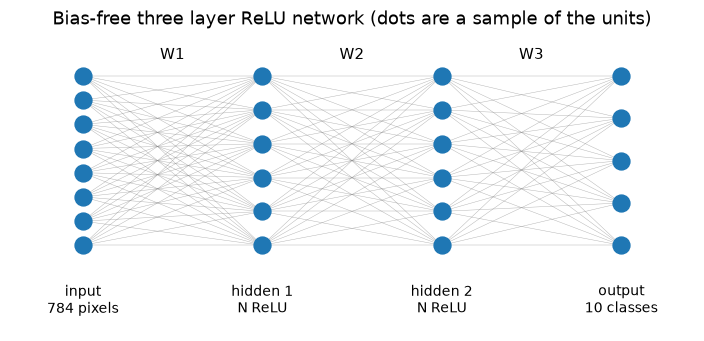

width  100:    89,400 weights
width  200:   198,800 weights
width  400:   477,600 weights
width  800: 1,275,200 weights


In [4]:
def draw_network(ax, shown=(8, 6, 6, 5)):
    xs = np.arange(4) * 2.0
    pos = [[(x, y) for y in np.linspace(-1, 1, n)] for x, n in zip(xs, shown)]
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b:
                ax.plot([p[0], q[0]], [p[1], q[1]], color="grey", lw=0.3, alpha=0.6)
    labels = ["input\n784 pixels", "hidden 1\nN ReLU", "hidden 2\nN ReLU", "output\n10 classes"]
    for x, layer, lab in zip(xs, pos, labels):
        ax.scatter(*zip(*layer), s=120, color="tab:blue", zorder=3)
        ax.text(x, -1.45, lab, ha="center", va="top", fontsize=9)
    for i, x in enumerate(xs[:-1]):
        ax.text(x + 1, 1.2, f"W{i + 1}", ha="center", fontsize=10)
    ax.set_xlim(-0.8, xs[-1] + 0.8); ax.set_ylim(-2, 1.5); ax.axis("off")
    ax.set_title("Bias-free three layer ReLU network (dots are a sample of the units)")

fig, ax = plt.subplots(figsize=(8, 3.5))
draw_network(ax)
plt.show()

torch.manual_seed(0)
for N in (100, 200, 400, 800):
    model = L.DeepBiasFreeMLP(784, N, 10, depth=3, scaling="standard", init_scale=7.0)
    print(f"width {N:4d}: {sum(p.numel() for p in model.parameters()):>9,} weights")

## 2. A typical grokking run

Width 200, s = 7, ηλ = 3e-6, three seeds. Training accuracy jumps to 1 near step 15000 while test accuracy is still below 0.2 (dashed line: memorisation). Test accuracy then climbs slowly and passes 0.80 around step 400000.

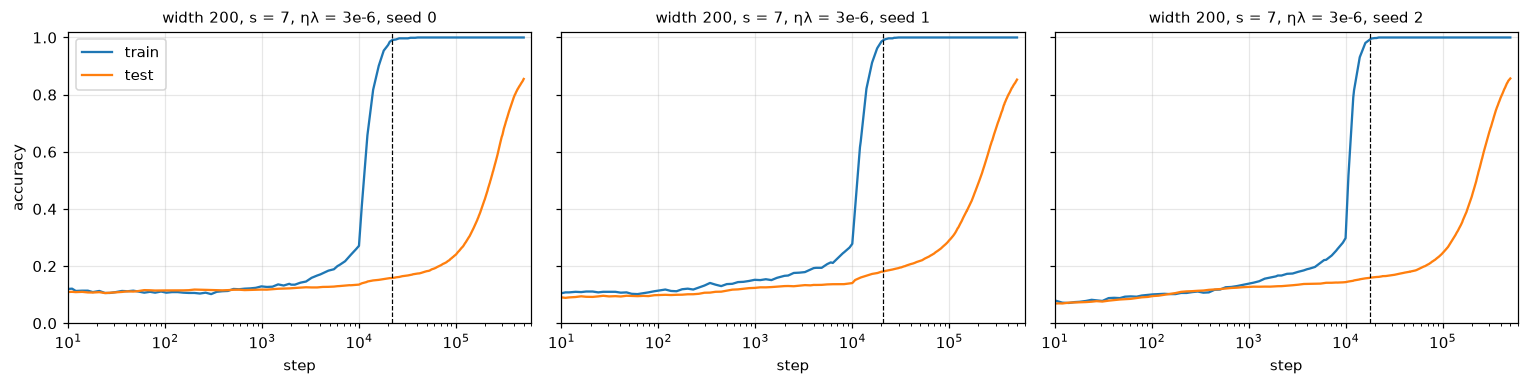

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, seed in zip(axes, range(3)):
    acc_panel(ax, f"optB_b3_curv_s7_ek3e-06_seed{seed}", f"width 200, s = 7, ηλ = 3e-6, seed {seed}")
    ax.set_xlabel("step")
axes[0].set_ylabel("accuracy"); axes[0].legend()
plt.tight_layout(); plt.show()

## 3. Effect of the initial scale

Width 200, ηλ = 3e-6, seed 0, with s = 3, 5, 7 and 9. A larger initial scale delays generalisation more. At s = 3 test accuracy rises together with training accuracy, so there is little delay. The runs at s = 3 and 5 were trained for 300000 steps.

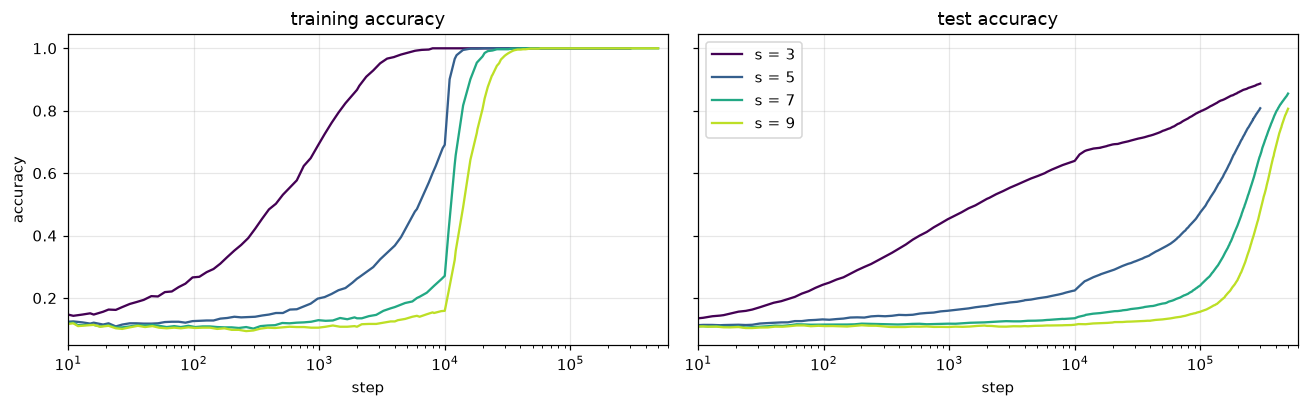

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colours = plt.cm.viridis(np.linspace(0, 0.9, 4))
for s, colour in zip((3, 5, 7, 9), colours):
    h, _ = history(f"optB_b3_curv_s{s}_ek3e-06_seed0")
    axes[0].plot(h["step"], h["train_acc"], color=colour, label=f"s = {s}")
    axes[1].plot(h["step"], h["test_acc"], color=colour, label=f"s = {s}")
for ax, t in zip(axes, ("training accuracy", "test accuracy")):
    ax.set_xscale("log"); ax.set_xlim(10, 6e5); ax.set_title(t); ax.set_xlabel("step")
axes[0].set_ylabel("accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Effect of weight decay

Width 200, s = 7, seed 0, with ηλ = 3e-6, 1e-5 and 2e-5. Stronger decay brings generalisation forward and also lifts the final test accuracy. At 2e-5 the gain comes too soon after memorisation to count as a strong delay.

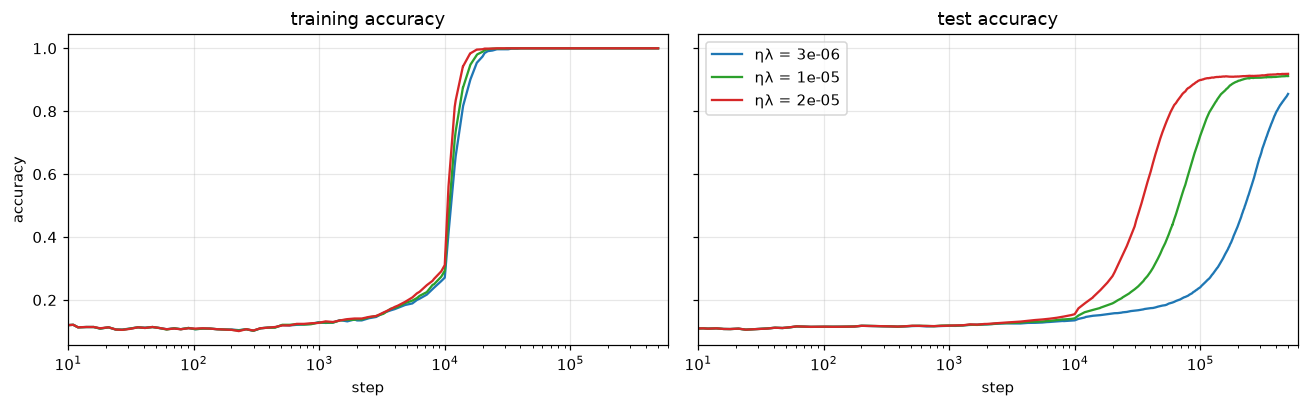

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ek, colour in zip(("3e-06", "1e-05", "2e-05"), ("tab:blue", "tab:green", "tab:red")):
    h, _ = history(f"optB_b3_curv_s7_ek{ek}_seed0")
    axes[0].plot(h["step"], h["train_acc"], color=colour, label=f"ηλ = {float(ek):g}")
    axes[1].plot(h["step"], h["test_acc"], color=colour, label=f"ηλ = {float(ek):g}")
for ax, t in zip(axes, ("training accuracy", "test accuracy")):
    ax.set_xscale("log"); ax.set_xlim(10, 6e5); ax.set_title(t); ax.set_xlabel("step")
axes[0].set_ylabel("accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

## 5. Effect of width

s = 7, ηλ = 3e-6, seed 0, with widths 100, 200, 400 and 800. Width 100 memorises late and generalises poorly. From width 200 up the curves nearly coincide, and the wider networks end slightly higher. The width 400 and 800 runs come from the grid pilot, which drew the training images with data seed 42 + seed, the same draw as the other runs for seed 0.

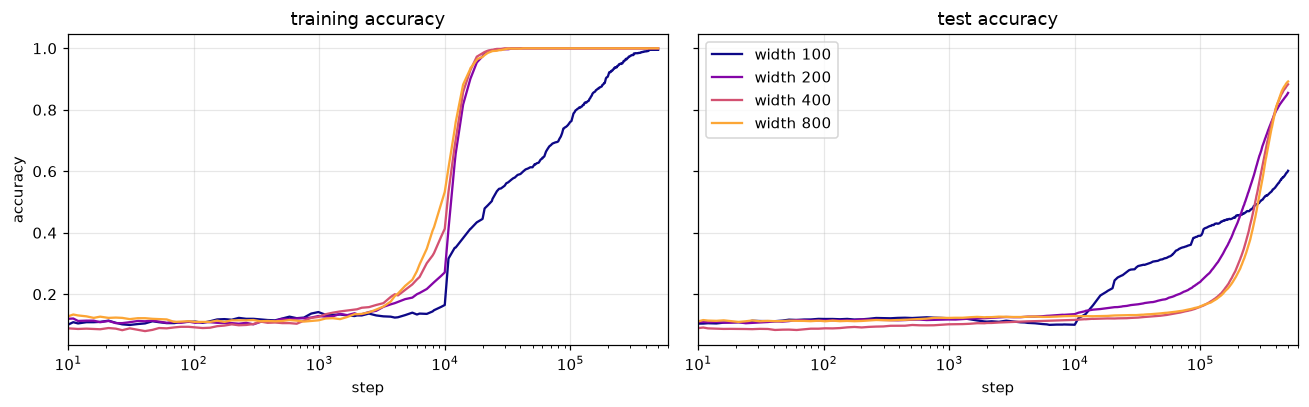

In [8]:
WIDTH_RUNS = {100: "optB_b4_curv_s7_ek3e-06_w100_seed0", 200: "optB_b3_curv_s7_ek3e-06_seed0",
              400: "grid_w400_s7_ek3e-06_seed0", 800: "grid_w800_s7_ek3e-06_seed0"}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for (N, name), colour in zip(WIDTH_RUNS.items(), plt.cm.plasma(np.linspace(0, 0.8, 4))):
    h, _ = history(name)
    axes[0].plot(h["step"], h["train_acc"], color=colour, label=f"width {N}")
    axes[1].plot(h["step"], h["test_acc"], color=colour, label=f"width {N}")
for ax, t in zip(axes, ("training accuracy", "test accuracy")):
    ax.set_xscale("log"); ax.set_xlim(10, 6e5); ax.set_title(t); ax.set_xlabel("step")
axes[0].set_ylabel("accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Weight norm and the learning rate rule

Left: test accuracy against the weight norm relative to its initial value, for the four initial scales of section 3. Omnigrok explains grokking as weight decay shrinking a large initial norm to a size at which the network generalises. The larger the initial scale, the further the weights have to shrink before test accuracy rises. At s = 3 it rises with almost no change of the norm. At s = 9 it reaches 0.5 only once the norm has fallen to about 40 percent of its start.

Right: the learning rate relative to η₀ = 1/λ₀ in the s = 7 run. The curvature of the loss falls as the weights shrink, and the rule raises the step to keep η times the top curvature fixed. The first reset, at step 10000, raises the rate about tenfold and triggers memorisation. With a fixed rate the strong grokking did not appear, so this rule is part of the setup and the kernel does not set a fixed step size in these runs.

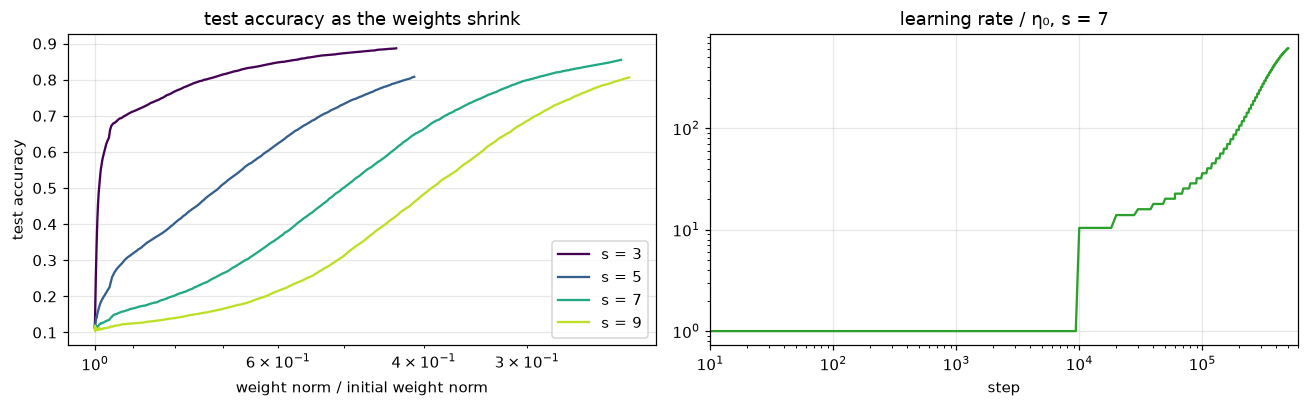

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for s, colour in zip((3, 5, 7, 9), colours):
    h, run = history(f"optB_b3_curv_s{s}_ek3e-06_seed0")
    axes[0].plot(h["weight_norm"] / run["init_weight_norm"], h["test_acc"], color=colour, label=f"s = {s}")
axes[0].set_xscale("log"); axes[0].invert_xaxis()
axes[0].set_xlabel("weight norm / initial weight norm"); axes[0].set_ylabel("test accuracy")
axes[0].set_title("test accuracy as the weights shrink"); axes[0].legend()
h, _ = history("optB_b3_curv_s7_ek3e-06_seed0")
axes[1].plot(h["step"], h["eta"] / h["eta"][0], color="tab:green")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlim(10, 6e5)
axes[1].set_xlabel("step"); axes[1].set_title("learning rate / η₀, s = 7")
plt.tight_layout(); plt.show()

## 7. The tangent kernel during grokking

The empirical kernel on the mixed probe, in closed form, for width 200, s = 7, ηλ = 3e-6, seed 0, with test accuracy in orange on the right axis. The kernel norm falls by a factor of several hundred while its shape changes by a few percent (R_t). The centred alignment A_t falls before memorisation and rises only after test accuracy has passed about 0.5, so on MNIST the alignment follows generalisation and does not lead it.

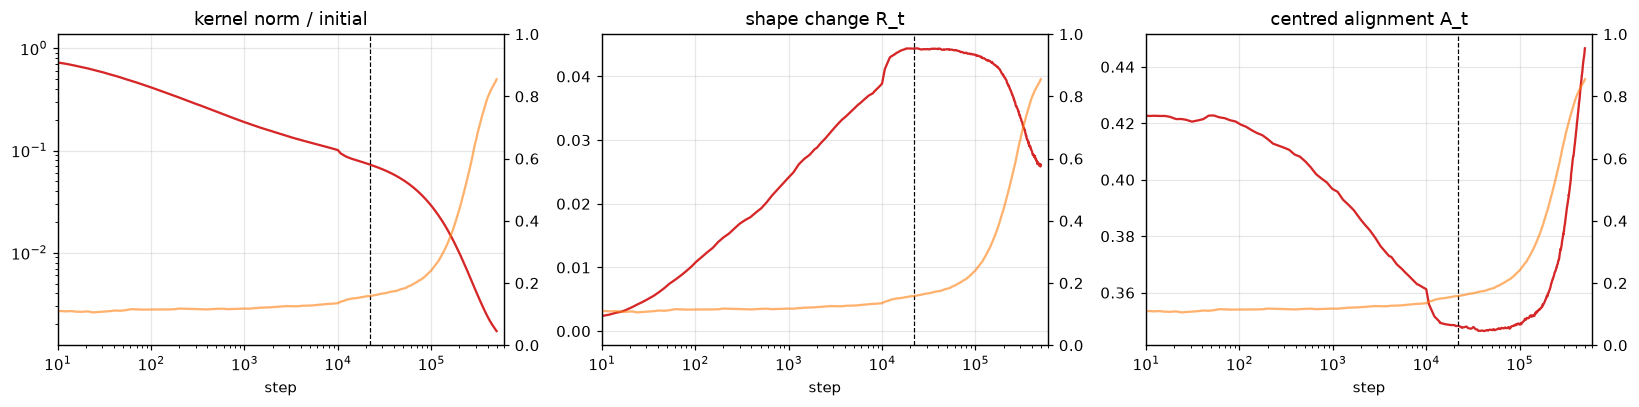

In [10]:
h, run = history("optB_b3_curv_s7_ek3e-06_seed0")
t_mem = crossing(h["step"], h["train_acc"], MEM_LEVEL)
panels = [(h["K_norm"] / h["K_norm"][0], "kernel norm / initial", True),
          (h["R_t"], "shape change R_t", False), (h["A_t"], "centred alignment A_t", False)]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (y, title, logy) in zip(axes, panels):
    ax.plot(h["step"], y, color="tab:red")
    if logy:
        ax.set_yscale("log")
    ax.set_xscale("log"); ax.set_xlim(10, 6e5); ax.set_xlabel("step"); ax.set_title(title)
    ax.axvline(t_mem, ls="--", color="k", lw=0.8)
    ax2 = ax.twinx()
    ax2.plot(h["step"], h["test_acc"], color="tab:orange", alpha=0.6)
    ax2.set_ylim(0, 1); ax2.grid(False)
plt.tight_layout(); plt.show()

## 8. Where grokking happens

Each cell is one initial scale and one weight decay at width 200, with the seeds the exploration ran (two or three). The colour is the median step at which test accuracy first reaches 0.80, and the text gives the number of strong verdicts out of the seeds. Strong grokking appears at s = 7 and 9 with ηλ up to 1e-5, and at s = 5 only with ηλ = 3e-6. Larger decay or a smaller scale makes the network generalise sooner, but without the delay. The verdicts here use memorisation at 0.99. The exploration report used 0.95, which counts one more seed at s = 5 as strong. The grid sweep will fill in this picture with five seeds, seven decay levels and four widths.

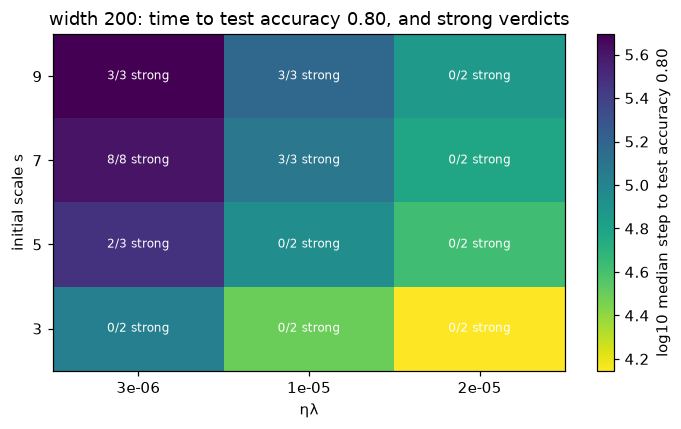

In [11]:
w200 = table[(table["width"] == 200)].copy()
w200 = w200[w200.index.str.contains("_b3_|_b2_curv|_b4_curv_s7_ek3e-06_seed")]
scales, decays = sorted(w200["init_scale"].unique()), sorted(w200["eta_kappa"].unique())
med = np.full((len(scales), len(decays)), np.nan)
text = np.empty((len(scales), len(decays)), dtype=object)
for i, s in enumerate(scales):
    for j, ek in enumerate(decays):
        g = w200[(w200["init_scale"] == s) & (w200["eta_kappa"] == ek)]
        if len(g):
            t = g["t_80"].astype(float)
            med[i, j] = np.nanmedian(t) if t.notna().sum() * 2 > len(g) else np.nan
            text[i, j] = f"{(g['verdict'] == 'strong').sum()}/{len(g)} strong"
fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(np.log10(med), cmap="viridis_r", origin="lower", aspect="auto")
for i in range(len(scales)):
    for j in range(len(decays)):
        if text[i, j]:
            ax.text(j, i, text[i, j], ha="center", va="center", fontsize=8, color="w")
ax.set_xticks(range(len(decays)), [f"{d:g}" for d in decays]); ax.set_xlabel("ηλ")
ax.set_yticks(range(len(scales)), [f"{s:g}" for s in scales]); ax.set_ylabel("initial scale s")
fig.colorbar(im, label="log10 median step to test accuracy 0.80")
ax.set_title("width 200: time to test accuracy 0.80, and strong verdicts"); ax.grid(False)
plt.tight_layout(); plt.show()